# 3. Ewaluacja modelu Perceptron (One-vs-Rest), analiza wag i błędów

W tym notatniku porównujemy na zamrożonym zbiorze testowym (`data/processed/test.csv`, $N = 690$) pięć podejść:
1. **Baseline 1 (`MajorityClassBaseline`)** — zawsze klasa `neutral`.
2. **Baseline 2 (`KeywordBaseline`)** — zliczanie słów ze słownika finansowego.
3. **Model 3 (`OneVsRestPerceptron` bazowy)** — klasyczny perceptron OvR ze `stop_words="english"`.
4. **Model 4 (`sklearn.linear_model.Perceptron`)** — referencyjna implementacja z biblioteki `scikit-learn`.
5. **Model 5 (`Averaged OneVsRestPerceptron` + `balanced`)** — nasza ulepszona wersja z uśrednianiem wag, kompensacją nierównowagi klas i zachowaniem słów kierunkowych (*up*, *down*, *not*).

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.baseline import MajorityClassBaseline, KeywordBaseline
from src.perceptron import OneVsRestPerceptron, evaluate_sklearn_perceptron

train_df = pd.read_csv(PROJECT_ROOT / "data/processed/train.csv")
test_df = pd.read_csv(PROJECT_ROOT / "data/processed/test.csv")

print(f"Zbiór uczący: {len(train_df)} zdań | Zbiór testowy: {len(test_df)} zdań")

Zbiór uczący: 2758 zdań | Zbiór testowy: 690 zdań


In [2]:
# Punkty odniesienia
preds_maj = MajorityClassBaseline().fit(train_df["label"]).predict(test_df["sentence"])
preds_kw = KeywordBaseline().fit().predict(test_df["sentence"])

# Wariant bazowy TF-IDF + Perceptron
vec_base = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), stop_words="english")
X_tr_base = vec_base.fit_transform(train_df["sentence"])
X_te_base = vec_base.transform(test_df["sentence"])

clf_base = OneVsRestPerceptron(learning_rate=0.1, n_epochs=15, averaged=False, random_state=42)
clf_base.fit(X_tr_base, train_df["label"])
preds_base = clf_base.predict(X_te_base)

# Wariant ulepszony TF-IDF (zachowanie słów kierunkowych up/down/not)
vec_imp = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    stop_words=None,
)
X_tr_imp = vec_imp.fit_transform(train_df["sentence"])
X_te_imp = vec_imp.transform(test_df["sentence"])

clf_imp = OneVsRestPerceptron(
    learning_rate=0.1,
    n_epochs=20,
    averaged=True,
    class_weight="balanced",
    random_state=42,
)
clf_imp.fit(X_tr_imp, train_df["label"])
preds_imp = clf_imp.predict(X_te_imp)

# Referencyjny model scikit-learn
sk_res = evaluate_sklearn_perceptron(X_tr_imp, train_df["label"], X_te_imp, test_df["label"])

summary_df = pd.DataFrame([
    {
        "Model": "Baseline 1: Klasa większościowa (neutral)",
        "Accuracy (%)": round(accuracy_score(test_df["label"], preds_maj) * 100, 2),
        "Macro-F1": round(f1_score(test_df["label"], preds_maj, average="macro"), 4),
    },
    {
        "Model": "Baseline 2: Słownik słów kluczowych",
        "Accuracy (%)": round(accuracy_score(test_df["label"], preds_kw) * 100, 2),
        "Macro-F1": round(f1_score(test_df["label"], preds_kw, average="macro"), 4),
    },
    {
        "Model": "Model 3: Własny OneVsRestPerceptron (bazowy)",
        "Accuracy (%)": round(accuracy_score(test_df["label"], preds_base) * 100, 2),
        "Macro-F1": round(f1_score(test_df["label"], preds_base, average="macro"), 4),
    },
    {
        "Model": "Model 4: sklearn.linear_model.Perceptron",
        "Accuracy (%)": sk_res["accuracy"],
        "Macro-F1": sk_res["macro_f1"],
    },
    {
        "Model": "Model 5: Własny Averaged OvR + balanced (finał)",
        "Accuracy (%)": round(accuracy_score(test_df["label"], preds_imp) * 100, 2),
        "Macro-F1": round(f1_score(test_df["label"], preds_imp, average="macro"), 4),
    },
])

display(summary_df)
print("\nRaport klasyfikacji dla modelu finałowego:")
print(classification_report(test_df["label"], preds_imp, digits=4))

,Model,Accuracy (%),Macro-F1
0,Baseline 1: Klasa większościowa (neutral),62.03,0.2552
1,Baseline 2: Słownik słów kluczowych,76.81,0.6804
2,Model 3: Własny OneVsRestPerceptron (bazowy),78.26,0.7174
3,Model 4: sklearn.linear_model.Perceptron,84.64,0.8015
4,Model 5: Własny Averaged OvR + balanced (finał),85.36,0.7976



Raport klasyfikacji dla modelu finałowego:
              precision    recall  f1-score   support

    negative     0.8793    0.6071    0.7183        84
     neutral     0.8662    0.9533    0.9077       428
    positive     0.8075    0.7303    0.7670       178

    accuracy                         0.8536       690
   macro avg     0.8510    0.7636    0.7976       690
weighted avg     0.8527    0.8536    0.8483       690



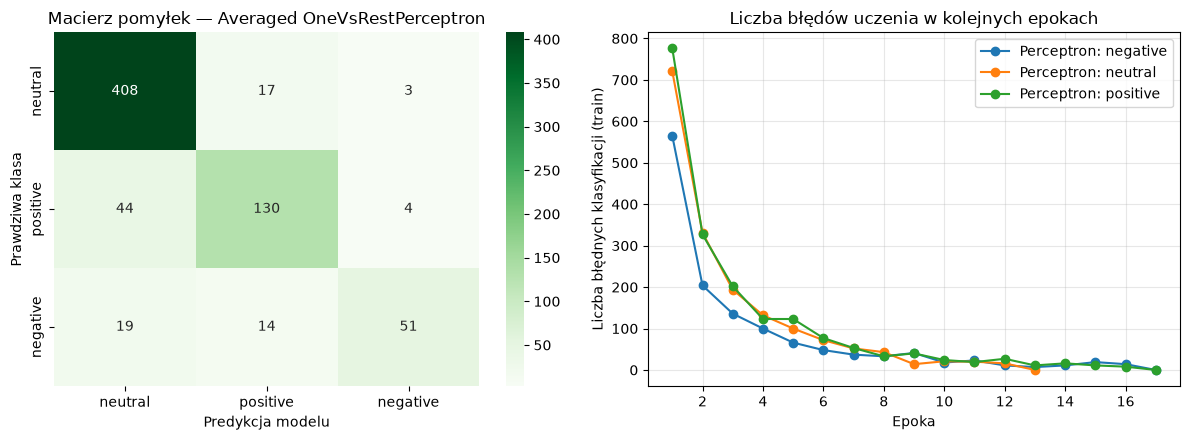

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

labels_order = ["neutral", "positive", "negative"]
cm = confusion_matrix(test_df["label"], preds_imp, labels=labels_order)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=labels_order, yticklabels=labels_order, ax=axes[0])
axes[0].set_title("Macierz pomyłek — Averaged OneVsRestPerceptron")
axes[0].set_xlabel("Predykcja modelu")
axes[0].set_ylabel("Prawdziwa klasa")

for cls_name, err_list in clf_imp.errors_history_.items():
    axes[1].plot(range(1, len(err_list) + 1), err_list, marker="o", label=f"Perceptron: {cls_name}")
axes[1].set_title("Liczba błędów uczenia w kolejnych epokach")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Liczba błędnych klasyfikacji (train)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results/perceptron_cm.png", dpi=150)
plt.show()

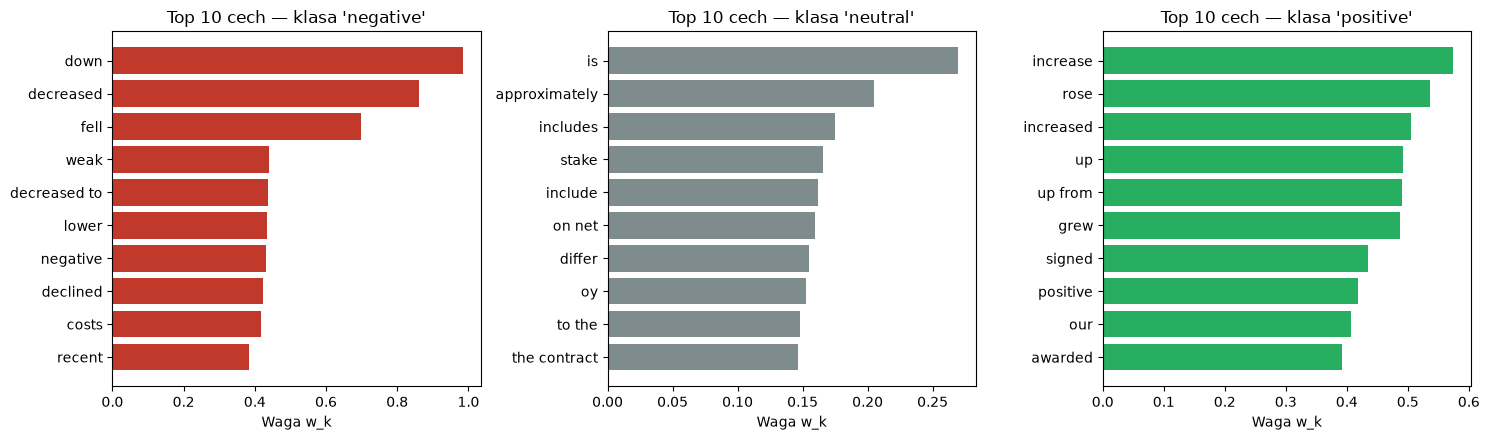

In [4]:
top_features = clf_imp.get_top_features(vec_imp.get_feature_names_out(), top_n=10)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colors = {"negative": "#c0392b", "neutral": "#7f8c8d", "positive": "#27ae60"}

for idx, cls_name in enumerate(["negative", "neutral", "positive"]):
    words = [item[0] for item in top_features[cls_name]][::-1]
    weights = [item[1] for item in top_features[cls_name]][::-1]
    axes[idx].barh(words, weights, color=colors[cls_name])
    axes[idx].set_title(f"Top 10 cech — klasa '{cls_name}'")
    axes[idx].set_xlabel("Waga w_k")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results/perceptron_top_features.png", dpi=150)
plt.show()

In [5]:
scores = clf_imp.decision_function(X_te_imp)
eval_df = test_df.copy()
eval_df["predicted"] = preds_imp
for idx, cls_name in enumerate(clf_imp.classes_):
    eval_df[f"Z_{cls_name}"] = scores[:, idx].round(3)

mistakes = eval_df[eval_df["label"] != eval_df["predicted"]]
print(f"Liczba błędnych predykcji na zbiorze testowym: {len(mistakes)} / {len(eval_df)}\n")
for _, row in mistakes.head(5).iterrows():
    print(f"Zdanie: {row['sentence']}")
    print(f"  Prawdziwa: {row['label']} | Predykcja: {row['predicted']} | Z=[neg:{row['Z_negative']}, neu:{row['Z_neutral']}, pos:{row['Z_positive']}]\n")

Liczba błędnych predykcji na zbiorze testowym: 101 / 690

Zdanie: The company said that sales in the three months to the end of March slid to EUR86 .4 m US$ 113.4 m from EUR91 .2 m last year .
  Prawdziwa: negative | Predykcja: positive | Z=[neg:0.013, neu:-0.171, pos:0.057]

Zdanie: F-Secure reported that : - The first half of 2008 has seen a growing number of targeted malware attacks on individuals , companies , and organizations .
  Prawdziwa: neutral | Predykcja: negative | Z=[neg:0.078, neu:-0.054, pos:-0.071]

Zdanie: The sale will result in a capital loss of EUR5m for Solidium , which obtained Tikkurila shares in March 2010 .
  Prawdziwa: negative | Predykcja: neutral | Z=[neg:-0.154, neu:-0.0, pos:-0.116]

Zdanie: Fiskars , the World 's  1 Scissors Brand TM , recently won Learning -« Magazine 's 2011 Teachers ' Choice Award for the Classroom .
  Prawdziwa: positive | Predykcja: neutral | Z=[neg:-0.246, neu:0.014, pos:-0.063]

Zdanie: Nokia Messaging 1.1 enables customers to rec